# TD 11: Correlation and Simple Linear Regression

Christelle Gonindard & Matthias Grenié

**This tutorial has two objectives:**

1. Determine whether a quantitative variable Y is linearly correlated with an explanatory quantitative variable X
2. If linear correlation exists, find a linear equation that predicts Y from X.


## 1. Application to genome size and gene number

### 1.1 Study background

The C value represents genome size. It is most often measured in pico-grams
(pg), or in number of nucleotide base pairs.

Variability being the substratum of evolution, it is rare to find constants in the living world.
living organisms. The first biologists to measure the mass of DNA in the nuclei
of eukarya cells found it remarkable that this value was constant:

1. between cells in different tissues of the same organism
2. between cells of different individuals of the same species.

This value is referred to as the **C-value**, the constant value of the mass of what we now call the genome.
genome. There is a relationship of proportionality between its mass and its length, so
C-value is also used to designate the size of the genome.

### 1.2 Unit of length

The basic monomer of DNA is the base pair.
pairs is often used as a unit of length. The following multiples are most commonly used:


- 1 kb = 10$^3$ bp
- 1 Mb = 10$^6$ bp
- 1 Gb = 10$^9$ bp

We have the following conversion relationship: $\text{number of base pairs} = \text{mass in pg} \times 0.97810^9$.
i.e.
- 1 kb $\approx$ 10$^{-6}$ pg
- 1 Mb $\approx$ 10$^{-3}$ pg
- 1 Gb $\approx$ 1 pg

The C-value is highly variable between species. Since this measure represents
the amount of genetic material in an organism, it is a priori reasonable to imagine the link
between C-value and morphological complexity.

The genomes of eukaryotes are composed in large part of DNA that does not code for proteins or elementary functions.
proteins or basic functions. It is therefore possible that a very large genome
contain only a very small proportion of informative material, which explains the absence
complexity.

To demonstrate the existence of non-coding DNA, we propose to analyze the relationship between genome size and the number of protein genes.
between genome size and the number of protein genes.

Retrieve the file `TD11_genes.txt` in the `data/` folder. 

This file contains the taxonomic domain of 53 species
to which they belong (virus, prokaryote and eukaryote) (`domain`), the species name (`species`), the C value expressed in Kb (`c_value`) and the number of prokinetic genes (`genes_number`).

The data were taken from J.W. Bimball's course:
http ://users.rcn.com/jkimball.ma.ultranet/BiologyPages/G/GenomeSizes.html.


**The questions asked in this first study are:**

1. Is there a link between genome size and number of genes?
2. If so, can we predict the number of genes as a function of genome size?

There are several steps to this analysis:

## 2. Data analysis

### 2.1. Reading and describing the data

The data are contained in the the file `TD11_genes.txt` in the `data/` folder

*Read the data, make a statistical summary and comment*. 

In [6]:
# Read data file
genes = read.table("data/TD11_genes.txt", sep = "\t", header = TRUE)


# Display start of data file contents 
head(genes)

summary(genes)

table(genes$domain)

,domain,species,c_value,genes_number
,<chr>,<chr>,<dbl>,<int>
1,Virus,Phi-X 174,5.386,10
2,Organelle,Human mitochondrion,16.569,37
3,Virus,Epstein-Barr virus (EBV),172.282,80
4,Prokaryote,Nanoarchaeum equitans,490.885,552
5,Organelle,nucleomorph of Guillardia theta,551.264,511
6,Prokaryote,Mycoplasma genitalium,580.073,483


    domain            species             c_value         genes_number  
 Length:61          Length:61          Min.   :      5   Min.   :   10  
 Class :character   Class :character   1st Qu.:   1551   1st Qu.: 1589  
 Mode  :character   Mode  :character   Median :   3268   Median : 2437  
                                       Mean   : 148468   Mean   : 5732  
                                       3rd Qu.:   6692   3rd Qu.: 5416  
                                       Max.   :3300000   Max.   :37544  


 Eukaryote  Organelle Prokaryote      Virus 
        15          2         41          3 

Firstly, it is important to note that this dataset contains species belonging to different domains: eukaryotes, prokaryotes, viruses. 

The first step in the analysis is to split the table into two sub-tables: one for eukaryotes and one for prokaryotes (we won't study the other domains, as there is too little data).
too little data). This split is important because the genomes of eukaryotes and prokaryotes are very different, for example:

- prokaryotic genes do not contain introns, unlike eukaryotic genes
- prokaryotic genomes have very few intergenic regions, unlike eukaryotic genes.

It is therefore illusory to attempt to create a single model to describe both species domains.

*Create a eu table containing only eukaryotes and a pro table containing only prokaryotes*.

In [7]:
# Tableau eu contains only eukaryotes
eu = genes[genes$domain == "Eukaryote",]

# Table pro which contains only prokaryotes
pro = genes[genes$domain == "Prokaryote",]

### 2.2. Question 1: Is there a linear correlation between Y=number of genes and X=genome size?

To get an idea of whether there is a linear correlation between two variables X and
Y, it's interesting to plot the point cloud between these two variables and check whether its shape
approximates a straight line for both tables:

*Plot the graphs and comment*.

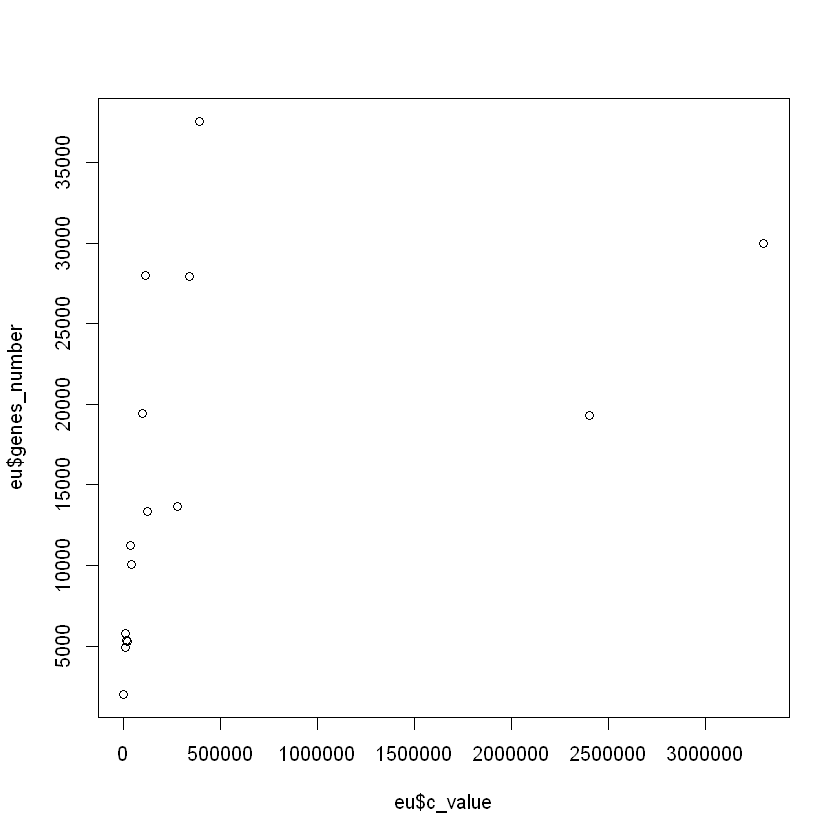

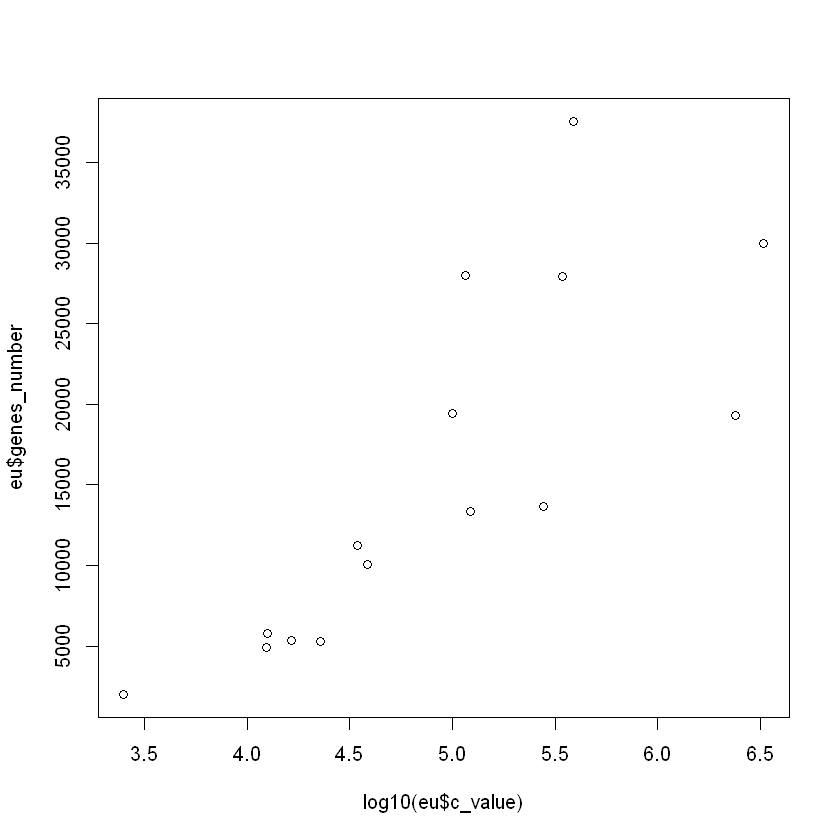

In [8]:
# Eukaryotes
plot(eu$c_value, eu$genes_number)

plot(log10(eu$c_value), eu$genes_number)

**Comment**:  
Difficult to see because of outliers without transformation.  
But seems like it with transformation

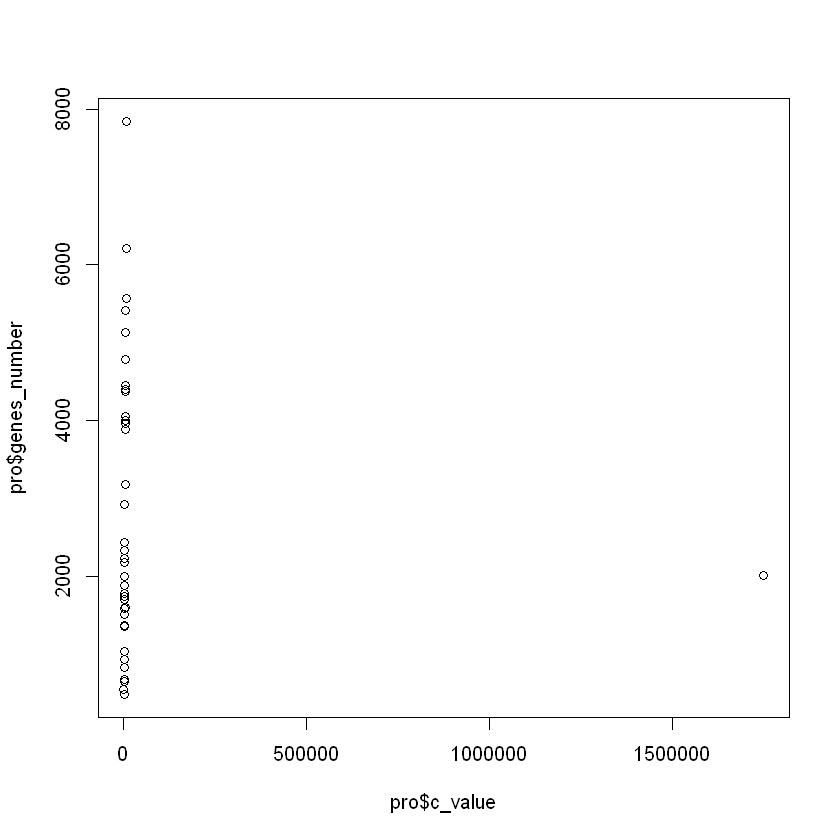

,domain,species,c_value,genes_number
,<chr>,<chr>,<dbl>,<int>
23,Prokaryote,Methanobacterium thermoautotrophicum,1751377,2008


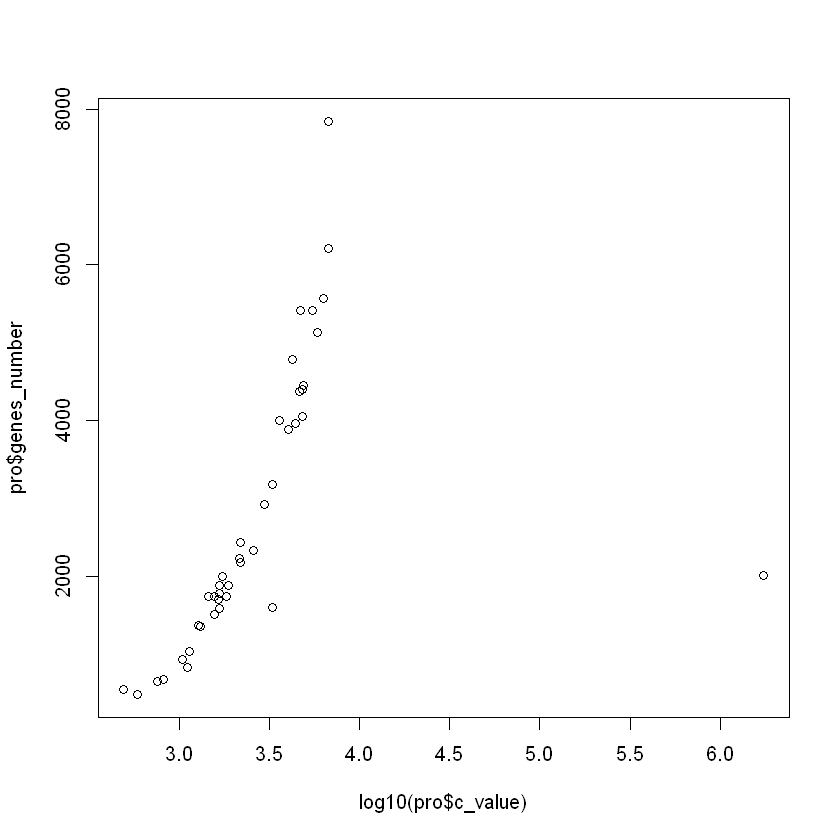

In [9]:
# Prokaryotes
plot(pro$c_value, pro$genes_number)

plot(log10(pro$c_value), pro$genes_number)

# Fishing the outlier
pro[log10(pro$c_value) > 6,]

**Comment**: 
Same even an exponential trend? or a cubic one, but there is a big outlier in prokaryotes with a C-value > 6 for a quite small number of genes

To ensure that this linear correlation really exists between the two variables, and that it is not due to sampling bias or simply chance, a test of the linear correlation coefficient is performed.
You can perform the test using the function `cor.test()` with the two first arguments being the two variables.

Specify H0 and H1


H0 : The number of genes is not correlated with genome size

H1 : The number of genes **is** correlated with genome size

*Compute the correlations between the variables genome size and number of genes for the two tables*.

In [10]:
# calculation of the linear correlation coefficient between 
# number of genes and genome size
# on the pro2 table 
cor.test(pro$c_value, pro$genes_number)


# calculation of the linear correlation coefficient between 
# number of genes and genome size
# on the eu table
cor.test(eu$c_value, eu$genes_number)


	Pearson's product-moment correlation

data:  pro$c_value and pro$genes_number
t = -0.38843, df = 39, p-value = 0.6998
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 -0.3628008  0.2503525
sample estimates:
        cor 
-0.06207937 



	Pearson's product-moment correlation

data:  eu$c_value and eu$genes_number
t = 1.8507, df = 13, p-value = 0.08707
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 -0.07260258  0.78522531
sample estimates:
      cor 
0.4566436 


**Comment**:
For prokaryote, we observe p = 0.7 >>> alpha = 0.05, so we can't reject H0, and as such there is no correlation between genome size and number of genes
While for eukaryote, we observe p = 0.087 which is close to alpha though superior, so we could say that we can't reject H0, and have a similar conclusions.

**However, if we apply a base-10 logarithmic transformation to the variables
and ValueC in the eukaryotic table, we can observe that in this case the linear
linear relationship seems much more realistic:**

*Assume: Y = log10(number of genes) and X = log10(C-Value), plot the new graph
and calculate the new linear correlation coefficient, then comment:*.


	Shapiro-Wilk normality test

data:  x
W = 0.96672, p-value = 0.8069



	Shapiro-Wilk normality test

data:  y
W = 0.94321, p-value = 0.4245



	Pearson's product-moment correlation

data:  x and y
t = 6.1839, df = 13, p-value = 3.303e-05
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.6307501 0.9539776
sample estimates:
      cor 
0.8638836 


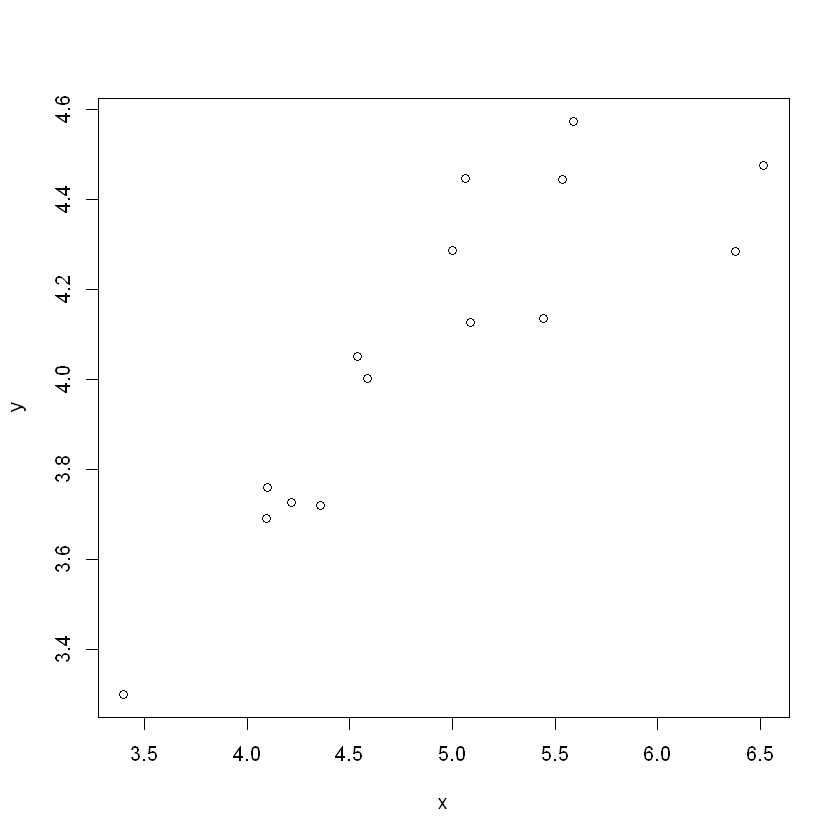

In [11]:
# Definition of variable Y
y = log10(eu$genes_number)

# Definition of variable X
x = log10(eu$c_value)

# Plot Y as a function of X
plot(x, y)

# Verification of data normality
shapiro.test(x)
shapiro.test(y)

# Calculation of linear correlation coefficient
cor.test(x, y)

**Conclusion**: 

In the rest of this study, we'll be looking at the eukaryotes table only.
but you can practise by doing the same study on prokaryotes.
We have just shown that there is a linear relationship between X and Y. 

We
now set up a model to predict the value of Y as a function of X, of the form
of X, of the form Y = aX + b, optimizing the values of a and b so that the line
is the best possible (see course).

Note that if we manage to determine this model $Y = aX + b$, then we'll be able to predict the number of genes in our genes.
predict the number of genes in a genome directly from its size (ValueC):

$$ Y =  aX + b$$

$$log_{10}(nb\_gene)=alog_{10}(ValueC) + b $$

$$\frac{ln(nb\_gene)}{ln(10)} = a\frac{ln(ValueC)}{ln(10)} + b $$

$$ln(nb\_gene) =a\frac{ln(ValueC)}{ln(10)} ln(10) + b ln(10)$$

$$ln(nb\_gene) =a ln(ValueC)+ b ln(10)$$

$$e^{ln(nb\_gene)} = e^{a ln(ValueC)+ b ln(10)}$$

$$nb\_gene = ValueC^a10^b$$


**In conclusion**: the relationship between the number of genes in a eukaryotic genome and its size
will be $$nb\_gene = ValueC^a10^b$$.

We'll now calculate the best possible values for a and b and validate this model.


### 2.3. Question 2: Construct the straight line that predicts Y as a function of X?

From the point cloud plotted above, several lines can be fitted to the shape of the cloud,
In the following, we'll calculate and plot the line (Y=aX+b) that best fits the point cloud
and check whether it is reasonable to use this line to predict the number of genes in a new eukaryotic genome. 

#### Calculation of model parameters

In [17]:
# Calculation of the linear regression line
euk_lin = lm(y ~ x)
summary(euk_lin)


Call:
lm(formula = y ~ x)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.31262 -0.13089 -0.00553  0.13969  0.32890 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  2.27495    0.29434   7.729 3.25e-06 ***
x            0.36413    0.05888   6.184 3.30e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.1915 on 13 degrees of freedom
Multiple R-squared:  0.7463,	Adjusted R-squared:  0.7268 
F-statistic: 38.24 on 1 and 13 DF,  p-value: 3.303e-05


**Comment**:

*Plot the point cloud and add the regression line to the graph*.

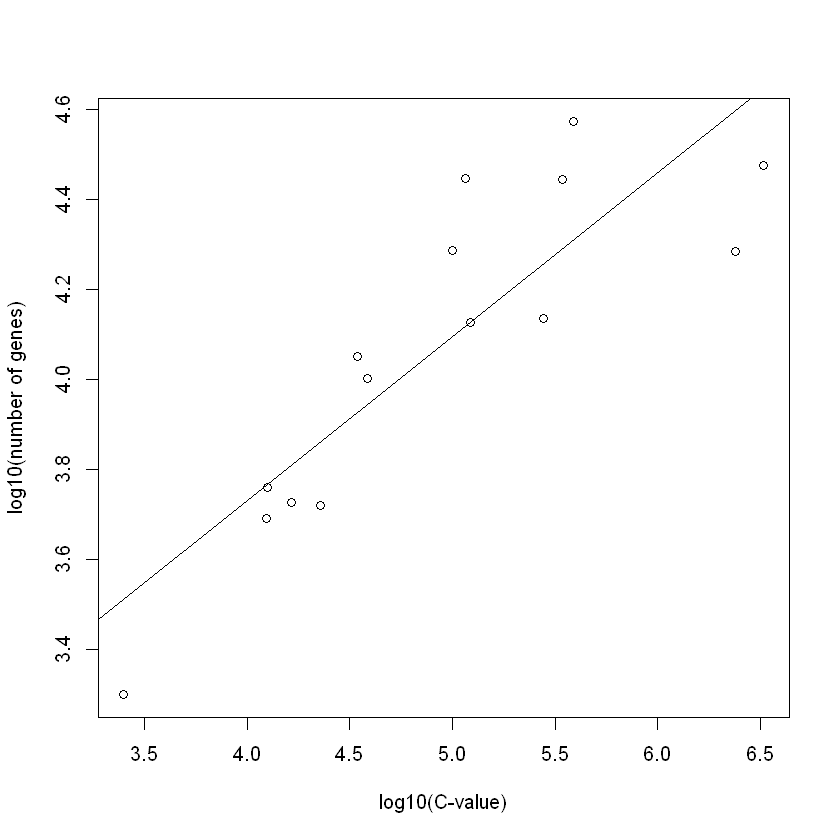

In [18]:
# Draw point cloud 
plot(x, y, xlab = "log10(C-value)", ylab = "log10(number of genes)")
# Use the abline() function to add a line
# so we'll add the linear regression line
# we've just calculated.
abline(euk_lin)

Next, it's important to understand that the software can calculate this straight line on any data set, even if it doesn't correspond to a straight line.
even if it doesn't correspond to a straight line. It is therefore important to
check :
- your data fits a straight line. 
- that the real data doesn't move too far away from the line (which represents the predictions), so that any prediction errors you make are considered negligible.

For this, the model validation step is essential.

#### Model validation

*1. Test the influence of variable X on the prediction of variable Y*.

**Is the equation Y = aX + b relevant?**

Is the linear model $Y = aX +b$ suitable for describing Y as a function of X in the population?

Does the X variable influence the prediction of the Y variable?

**Test on the slope: Wald's test**

In this example, the coefficient a is estimated by the value 0.4, which is close to zero.
If we had sampled more values, perhaps this parameter a would be even closer to
0 or even equal to 0, in which case, if the equation becomes y = b, y no longer depends on
x and the linear model is no longer appropriate.

To do this, we carry out a test comparing the slope to 0 to verify the link between y and x.

Specify H0 and H1

H0 : The slope is not different from 0

H1 : The slope is different from 0

The principle of this test is simple: it looks at the difference between the parameter $a$ and the value 0:

$$T=\frac{a-0}{S_a}$$

If this deviation is sufficiently far from 0, then a is considered to be different from 0, and the variable x will be able to predict y.
variable x will predict y.

*Perform the Wald test and conclude*.

In [19]:
# Test de Wald
summary(euk_lin)


Call:
lm(formula = y ~ x)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.31262 -0.13089 -0.00553  0.13969  0.32890 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  2.27495    0.29434   7.729 3.25e-06 ***
x            0.36413    0.05888   6.184 3.30e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.1915 on 13 degrees of freedom
Multiple R-squared:  0.7463,	Adjusted R-squared:  0.7268 
F-statistic: 38.24 on 1 and 13 DF,  p-value: 3.303e-05


Comment:  
We observe p = 3.3⋅10⁻⁵ <<< alpha = 0.05, so we reject H0, and the slope is different from 0

This test is simple, but it has the disadvantage of being conservative, i.e. it will have difficulty detecting a link between x and y if the latter is weak.

*2. Goodness of fit: Coefficient of determination $R^2$ (squared correlation coefficient)*.

The coefficient of determination is an indicator of the quality of a linear regression.
regression. It measures how well the model fits the observed data, or how well the regression equation
the regression equation is adapted to describe the distribution of points.

**It therefore measures the
proportion of the total variance of Y explained by X.**

It varies between 0 and 1, i.e. between low and high predictive power.
The value of the coefficient of determination is contained in the summary.
R-squared”. 

Specify the hypotheses H0 and H1 you test on $R^2$.

H0: R² is equal to 0

H1: R² is different from 0

*Calculate $R^2$, perform the test and conclude*.

In [22]:
# R2 and its significance test
# Look at the bottom of the following line
summary(euk_lin)
# We see an R-squared of 0.7463 with a p = 3⋅10⁻⁵ <<< alpha = 0.05, so we reject H0, and R² is different from 0.


Call:
lm(formula = y ~ x)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.31262 -0.13089 -0.00553  0.13969  0.32890 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  2.27495    0.29434   7.729 3.25e-06 ***
x            0.36413    0.05888   6.184 3.30e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.1915 on 13 degrees of freedom
Multiple R-squared:  0.7463,	Adjusted R-squared:  0.7268 
F-statistic: 38.24 on 1 and 13 DF,  p-value: 3.303e-05


In [23]:
# Variance decomposition
summary.aov(euk_lin)
# Total variability = Variability explained by model + residual variability
# (0.4768 + 1.4026= = 1.4026 + 0.4768

            Df Sum Sq Mean Sq F value  Pr(>F)    
x            1 1.4026  1.4026   38.24 3.3e-05 ***
Residuals   13 0.4768  0.0367                    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

**Comment**:

*3. Residuals study*

It is important that the errors made during prediction, i.e. the difference between the true value and the value predicted by our equation, are not too great (close to
the true value and the value predicted by our equation are not too large (close to 0)
and that they are homogeneous for all individuals. We therefore need to check certain conditions
before accepting the model. To do this, we use the studentized residuals (errors), i.e. the residuals divided by their standard deviation.
residuals divided by their standard deviation.

It is important that the residuals (errors made during predictions) satisfy certain
conditions before accepting the model. For this, studentized residuals are used, i.e. residuals divided by their standard deviation.
residuals divided by their standard deviation, in order to have a comparable criterion whatever the dataset analyzed.


$$ \text{residual} =\text{true value - predicted value} $$

$$ \text{residual}_{\text{Student}}=\frac{\text{residual}}{S_{\text{residual}}}$$


Check that :
- the normality of the studentized residuals (mean 0 and standard deviation 1) (shapiro test but generally not very powerful due to low sampling)
- The residuals are homogeneous, i.e. their dispersion is homogeneous and does not depend on the values of the explanatory variable (and therefore not on the predicted values either).

<img src="figures_1/homogeneite_residus.jpg" />


These two conditions can be checked on the residual graph. Simply project
the studentized residuals:
- have 95% of the residuals lie between the values -2 and 2. Otherwise, if there are many poorly explained points (outside the band), the model is poorly chosen.


<img src="Figures/loi_normale_residus.jpg" />


*Draw the graph representing the residuals and conclude*.


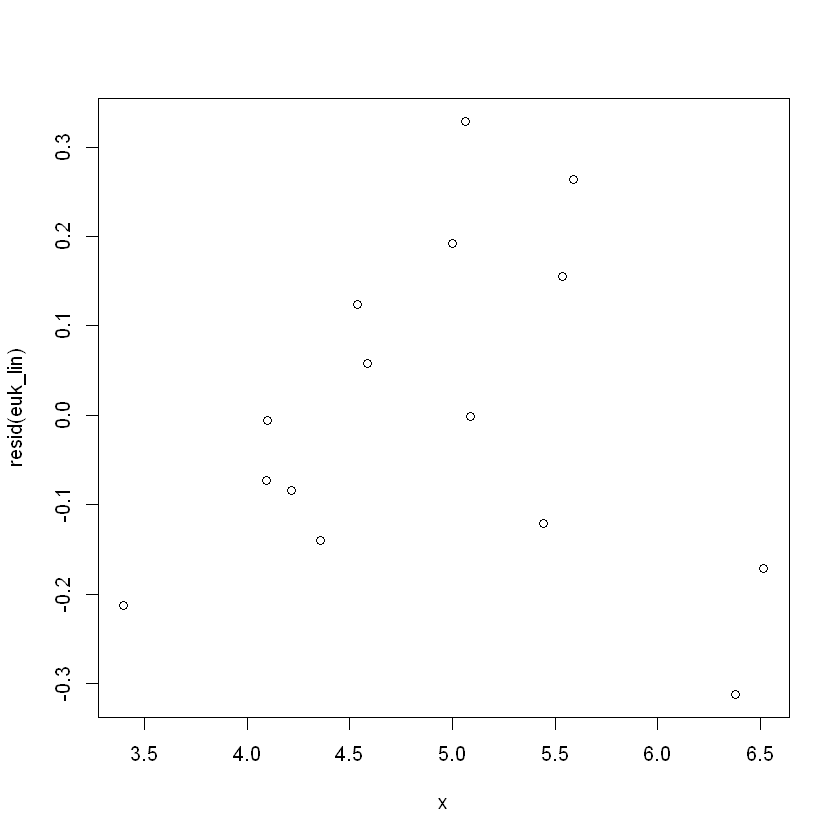

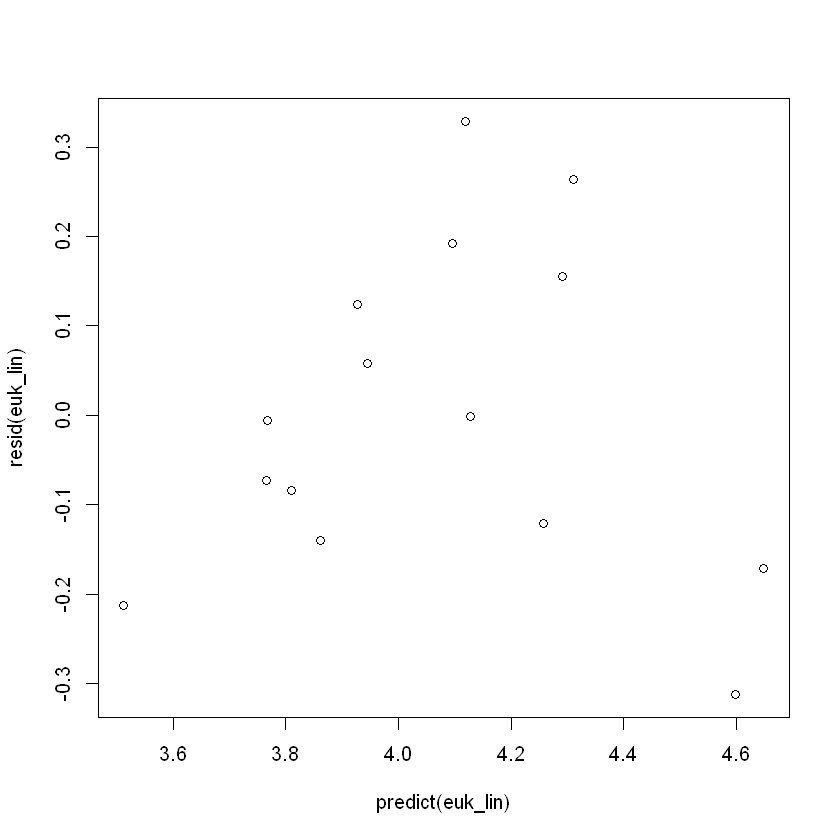

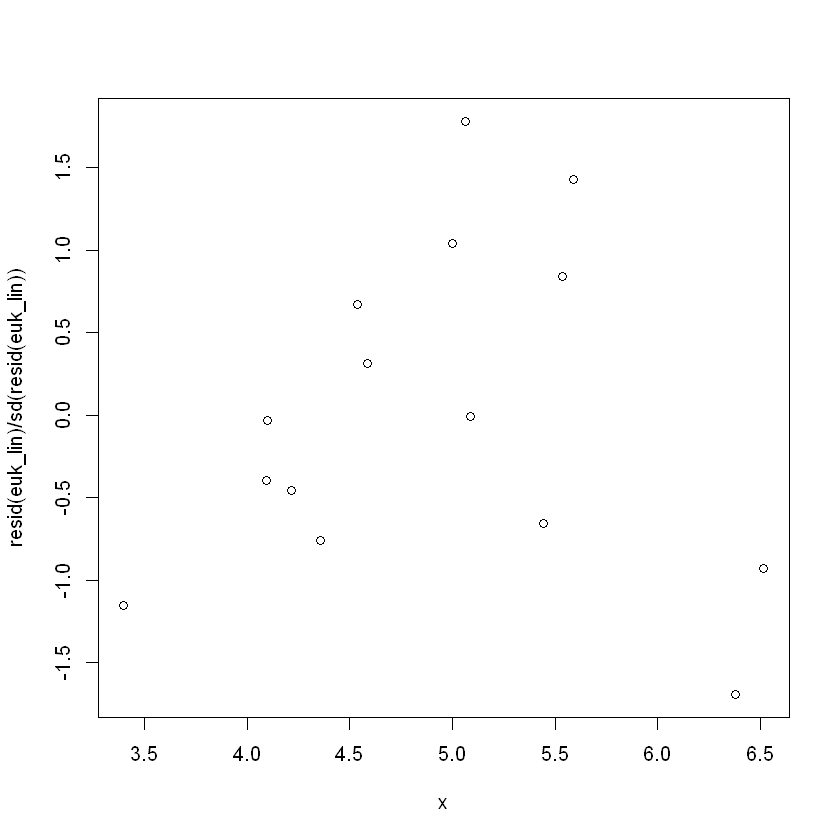

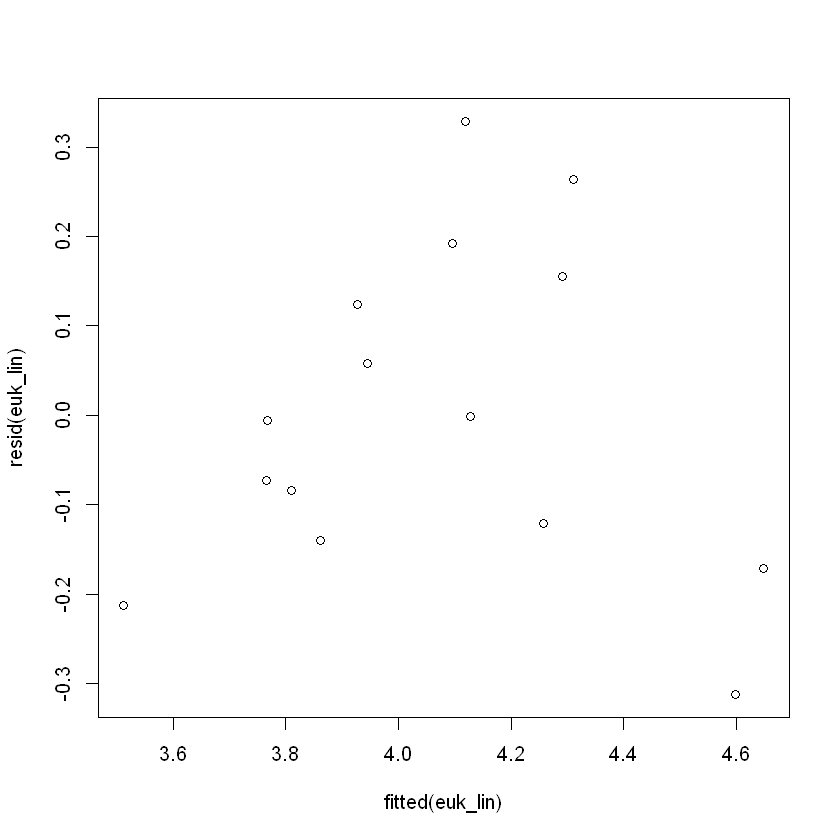

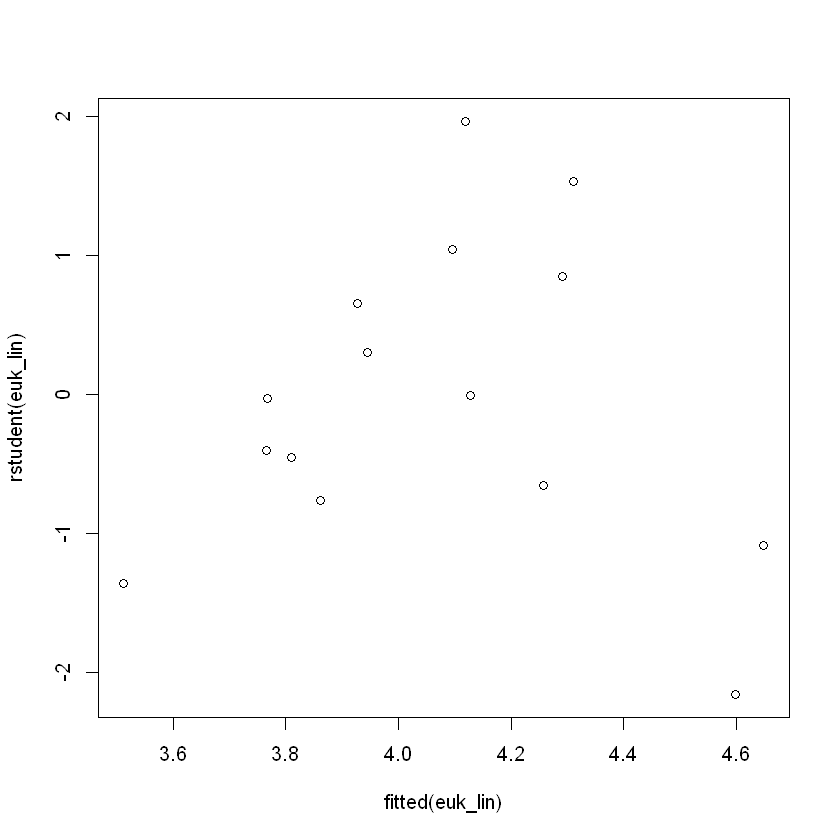

In [31]:
# Plot of residuals
plot(fitted(euk_lin), rstudent(euk_lin))

**Comment**:  
We observe that all Studentized residuals are between -2 and 2.

## 3. Exercise

In a sample of twelve pregnant women, lactogenic hormone is measured in amniotic
amniotic fluid and circulating blood. The results obtained are in the file `TD11_exercise_regression.txt` in the `data/` folder.

Perform a linear regression analysis as presented in the tutorial, then answer the following questions
the following questions: (Note: all answers to the questions are contained in your
in your analysis)

1. Are the assumptions for building a linear model verified?
2. Determine the linear correlation coefficient r between x and y in the sample.
3. Determine the equation of the fitted regression line from y to x.
4. Check the quality of your model.
5. Is there a relationship between levels of the hormone lactogne in amniotic fluid and in blood, at risk of error = 5%? and = 1%?

,patient,amniotic_fluid,blood
,<int>,<int>,<dbl>
1,1,12,4.8
2,2,8,3.9
3,3,15,7.3
4,4,13,6.7
5,5,11,4.3
6,6,12,5.6


[1] 12  3

    patient      amniotic_fluid      blood      
 Min.   : 1.00   Min.   : 7.00   Min.   :3.900  
 1st Qu.: 3.75   1st Qu.: 9.75   1st Qu.:4.300  
 Median : 6.50   Median :12.00   Median :5.250  
 Mean   : 6.50   Mean   :11.58   Mean   :5.417  
 3rd Qu.: 9.25   3rd Qu.:13.00   3rd Qu.:6.400  
 Max.   :12.00   Max.   :16.00   Max.   :7.300  


	Pearson's product-moment correlation

data:  reg$blood and reg$amniotic_fluid
t = 2.6899, df = 10, p-value = 0.02271
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.1178292 0.8906419
sample estimates:
      cor 
0.6479171 



Call:
lm(formula = amniotic_fluid ~ blood, data = reg)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.9949 -0.8649  0.1419  1.1072  3.3294 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)  
(Intercept)   3.7146     2.9914   1.242   0.2427  
blood         1.4527     0.5401   2.690   0.0227 *
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 2.167 on 10 degrees of freedom
Multiple R-squared:  0.4198,	Adjusted R-squared:  0.3618 
F-statistic: 7.235 on 1 and 10 DF,  p-value: 0.02271


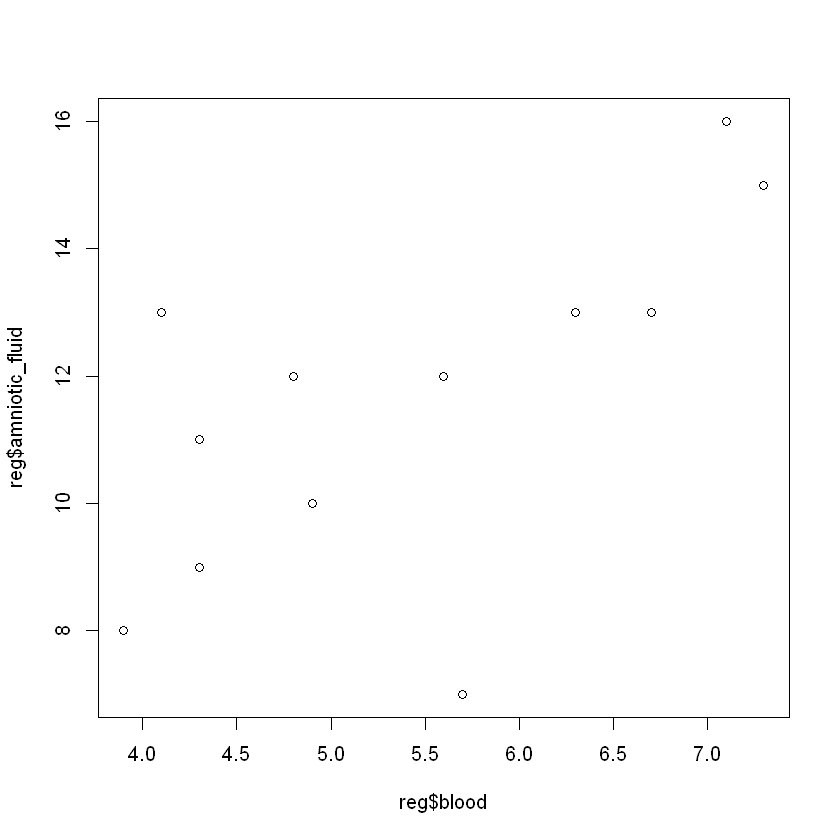

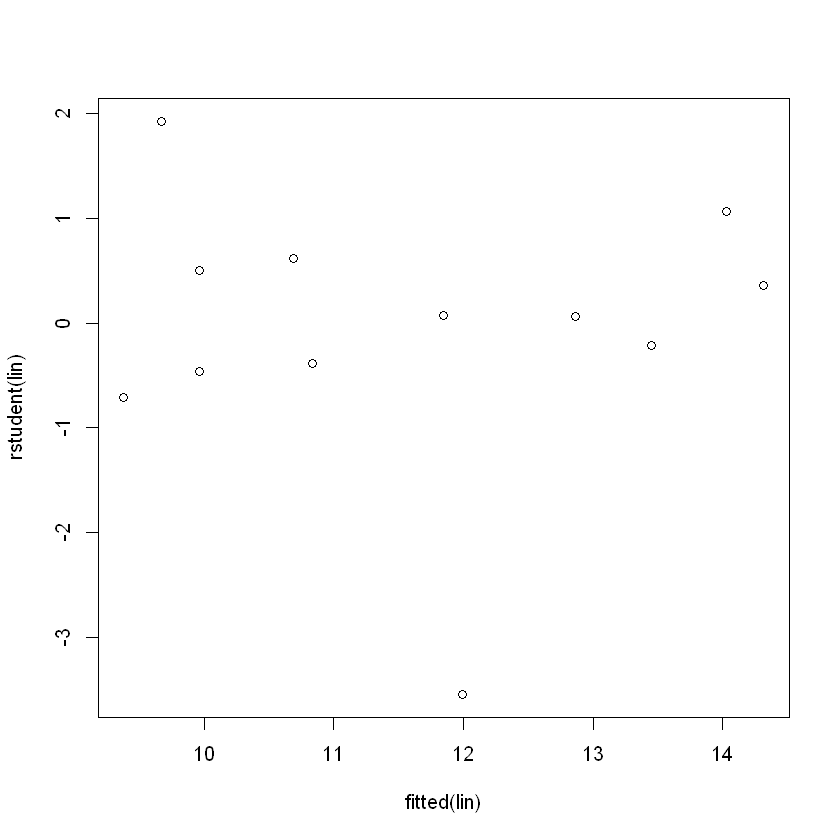

In [36]:
reg = read.table("data/TD11_exercise_regression.txt", header = TRUE)
head(reg)
dim(reg)
summary(reg)
plot(reg$blood, reg$amniotic_fluid)

cor.test(reg$blood, reg$amniotic_fluid)

lin = lm(amniotic_fluid ~ blood, data = reg)

summary(lin)
plot(fitted(lin), rstudent(lin))

# => at 5% yes there is a relationship, but not at 1%